In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score

df = pd.read_csv("../data/kbbi_v.csv")
print(df.shape)
df[["nama", "kelas", "submakna"]].head()

(146280, 16)


,nama,kelas,submakna
0,(air) susu dibalas dengan (air) tuba,NaN,kebaikan dibalas dengan kejahatan
1,(bagai) duri dalam daging,NaN,sesuatu yang selalu menyakitkan hati atau meng...
2,(me)rentan hati,NaN,"lekas marah (sakit hati, patah hati)"
3,(persetujuan) masih di perawanan,NaN,masih jauh (belum lagi tentu)
4,(sebagai durian) pangsa menunjukkan bangsa (se...,NaN,kelakuan (perkataan dan sebagainya) seseorang ...


In [2]:
# data: tebak kelas kata dari teks makna
data = df.dropna(subset=["kelas", "submakna"]).copy()
data["kelas_utama"] = data["kelas"].str.split(";").str[0].str.strip()
data = data[data["kelas_utama"].isin(["Nomina", "Verba", "Adjektiva"])]
data = data.groupby("kelas_utama").sample(1500, random_state=42)

data[["nama", "kelas_utama", "submakna"]].to_csv("../data/kbbi_sampel.csv", index=False)  # dipakai di notebook berikutnya

X_train, X_test, y_train, y_test = train_test_split(
    data["submakna"], data["kelas_utama"], test_size=0.2, random_state=42, stratify=data["kelas_utama"])

In [3]:
# pemrograman eksplisit: aturan ditulis manual
def tebak_manual(makna):
    if makna.startswith(("me", "ber", "ter")):
        return "Verba"
    if "tidak" in makna or "sangat" in makna:
        return "Adjektiva"
    return "Nomina"

print(f"Akurasi aturan manual: {accuracy_score(y_test, X_test.apply(tebak_manual)):.1%}")

Akurasi aturan manual: 64.7%


In [4]:
# machine learning: aturan dipelajari dari data berlabel
vec = TfidfVectorizer(max_features=3000, min_df=2)
X_train_v = vec.fit_transform(X_train)
X_test_v = vec.transform(X_test)

model = LogisticRegression(max_iter=1000).fit(X_train_v, y_train)
print(f"Akurasi model ML: {accuracy_score(y_test, model.predict(X_test_v)):.1%}")

Akurasi model ML: 71.4%


In [5]:
# tipe ML: supervised (ada label kelas, sudah di atas), unsupervised (tanpa label, di bawah)
# reinforcement tidak cocok karena KBBI data tetap tanpa lingkungan dan reward
umum = ["yang", "dan", "atau", "dengan", "untuk", "dalam", "tentang", "dapat", "ada", "sebagainya", "orang", "tidak"]
vec_k = TfidfVectorizer(max_features=1000, min_df=3, stop_words=umum)
X_k = vec_k.fit_transform(data["submakna"])

km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_k)
istilah = vec_k.get_feature_names_out()
for i, pusat in enumerate(km.cluster_centers_):
    print(f"Kelompok {i}:", ", ".join(istilah[pusat.argsort()[-6:][::-1]]))

Kelompok 0: berkaitan, bersifat, bumi, seperti, sifat, suatu
Kelompok 1: bersifat, dari, sesuatu, ke, sudah, sama
Kelompok 2: pada, bagian, dari, saat, tertentu, waktu
Kelompok 3: di, tengah, atas, provinsi, luar, bagian


In [6]:
pd.DataFrame({
    "Level": ["AI", "Machine Learning", "Deep Learning"],
    "Contoh pada KBBI": ["Asisten virtual penjawab arti kata", "Model penebak kelas kata di atas", "Model bahasa yang memahami kalimat utuh"],
})

,Level,Contoh pada KBBI
0,AI,Asisten virtual penjawab arti kata
1,Machine Learning,Model penebak kelas kata di atas
2,Deep Learning,Model bahasa yang memahami kalimat utuh


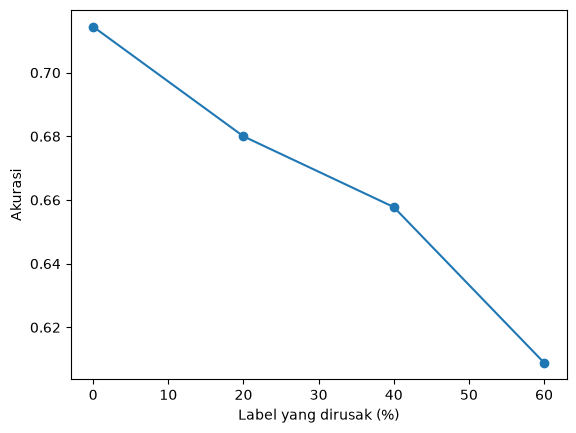

In [7]:
# garbage in, garbage out: rusak sebagian label latih lalu lihat akurasinya
rng = np.random.default_rng(42)
kelas = ["Nomina", "Verba", "Adjektiva"]
persen_rusak, akurasi = [0, 0.2, 0.4, 0.6], []

for p in persen_rusak:
    y_kotor = y_train.to_numpy().copy()
    rusak = rng.random(len(y_kotor)) < p
    y_kotor[rusak] = rng.choice(kelas, rusak.sum())
    m = LogisticRegression(max_iter=1000).fit(X_train_v, y_kotor)
    akurasi.append(accuracy_score(y_test, m.predict(X_test_v)))

plt.plot([p * 100 for p in persen_rusak], akurasi, marker="o")
plt.xlabel("Label yang dirusak (%)")
plt.ylabel("Akurasi")
plt.show()

In [8]:
# refleksi: ML di sekitar saya
pd.DataFrame({
    "Aplikasi": ["YouTube", "Gmail", "Instagram"],
    "Fitur": ["Rekomendasi video", "Filter spam", "Halaman Explore"],
    "Data": ["Riwayat tontonan dan like", "Isi dan pengirim email", "Postingan yang disukai dan disimpan"],
    "Prediksi": ["Video yang mungkin disukai", "Spam atau bukan", "Konten yang mungkin menarik"],
})

,Aplikasi,Fitur,Data,Prediksi
0,YouTube,Rekomendasi video,Riwayat tontonan dan like,Video yang mungkin disukai
1,Gmail,Filter spam,Isi dan pengirim email,Spam atau bukan
2,Instagram,Halaman Explore,Postingan yang disukai dan disimpan,Konten yang mungkin menarik


## Analisis

Aturan manual yang ditulis sendiri (awalan me, ber, ter dan kata tidak atau sangat) hanya mencapai akurasi 64,7 persen, sedangkan model machine learning dengan TF-IDF dan regresi logistik mencapai 71,4 persen pada data uji yang sama. Selisih 6,7 poin ini muncul karena model menemukan sendiri pola dari 3.600 data latih berlabel, sementara aturan manual hanya sebatas dugaan penulisnya. Pada K-Means tanpa label, kelompok yang terbentuk sudah punya ciri kata kunci yang berbeda, misalnya satu kelompok berisi bersifat, berhubungan, dan berkaitan, sedangkan kelompok lain berisi perbuatan, cara, dan proses. Artinya data teks makna memang punya pola yang bisa ditemukan tanpa diberi tahu kelasnya.

Percobaan garbage in, garbage out menunjukkan bahwa kualitas label menentukan kualitas model. Saat 0, 20, 40, dan 60 persen label latih dirusak, akurasi turun bertahap dari 71,4 persen menjadi 68,0, 65,8, dan 60,9 persen. Penurunannya tidak langsung drastis karena label yang dirusak secara acak kadang kebetulan tetap benar, tetapi tren turunnya jelas, sehingga data yang kotor tidak bisa diselamatkan hanya dengan model yang bagus.